# FGAI Assignment 3 — Vidya R Nayak (230911018)
**English → Spanish Neural Machine Translation** | ICT4403 | Basic Transformer, mT5, LLaMA 3.2 1B Instruct, Gemma 3 1B IT.

Run cells in order on a Colab T4 GPU. The notebook uses real measurements only; no scores are prefilled. Hugging Face Colab secret name: `fgai`.

## 1. Environment

In [1]:
%pip install -q "transformers==4.57.6" "huggingface-hub==0.36.2" "datasets==4.8.5" "tokenizers==0.22.2" sentencepiece sacrebleu accelerate bitsandbytes pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import torch
import transformers
import datasets
import huggingface_hub
import sentencepiece
import sacrebleu
import accelerate
import peft
import bitsandbytes

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("All required imports successful!")

GPU: Tesla T4
Transformers: 4.57.6
Datasets: 4.8.5
Hugging Face Hub: 0.36.2
All required imports successful!


In [3]:
import os, gc, time, re, math, json, random
import numpy as np, pandas as pd, torch, torch.nn as nn
from collections import Counter
from torch.utils.data import DataLoader, Dataset as TorchDataset
from torch.nn.utils.rnn import pad_sequence
import sacrebleu
random.seed(42); np.random.seed(42); torch.manual_seed(42)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device,torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

Device: cuda Tesla T4


## 2. Public parallel corpus — OPUS Books, English–Spanish
Source: https://huggingface.co/datasets/Helsinki-NLP/opus_books . Filter sentence lengths, shuffle deterministically, then split 4,800 / 600 / 600. The **same 100 held-out test sentences** are used for every model.

In [4]:
from datasets import load_dataset, Dataset
raw=load_dataset('Helsinki-NLP/opus_books','en-es',split='train')
pairs=[]
for row in raw:
    tr=row['translation']; en=tr['en'].strip(); es=tr['es'].strip()
    if en and es and 3<=len(en.split())<=35 and 3<=len(es.split())<=40:
        pairs.append({'en':en,'es':es})
assert len(pairs)>=6000, f'Only {len(pairs)} valid pairs available'
clean=Dataset.from_list(pairs).shuffle(seed=42).select(range(6000))
split=clean.train_test_split(test_size=.2,seed=42)
other=split['test'].train_test_split(test_size=.5,seed=42)
train_data,val_data,test_data=split['train'],other['train'],other['test']
eval_data=test_data.select(range(100)); sources=list(eval_data['en']); references=list(eval_data['es'])
print('Train/val/test:',len(train_data),len(val_data),len(test_data)); print(train_data[0])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

en-es/train-00000-of-00001.parquet:   0%|          | 0.00/16.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

Train/val/test: 4800 600 600
{'en': '"It might have been difficult, but friend Lestrade held information in his hands the value of which he did not himself know.', 'es': '––Podría haber resultado dificil, pero el amigo Lestrade tenía en sus manos una información cuyo valor desconocía.'}


## 3. Basic Transformer — train from scratch

In [5]:
SPECIAL=['<pad>','<unk>','<bos>','<eos>']
def tokenize(s): return re.findall(r"\w+|[^\w\s]",s.lower(),flags=re.UNICODE)
def vocab_for(texts,max_size=8000):
    c=Counter()
    for t in texts: c.update(tokenize(t))
    return {w:i for i,w in enumerate(SPECIAL+[w for w,_ in c.most_common(max_size-4) if w not in SPECIAL])}
src_vocab=vocab_for(train_data['en']); tgt_vocab=vocab_for(train_data['es'])
def encode(s,v,max_len=40):
    ids=[v['<bos>']]+[v.get(w,v['<unk>']) for w in tokenize(s)]
    return ids[:max_len-1]+[v['<eos>']]
class Pairs(TorchDataset):
    def __init__(self,d):self.d=d
    def __len__(self):return len(self.d)
    def __getitem__(self,i):
        r=self.d[i];return torch.tensor(encode(r['en'],src_vocab)),torch.tensor(encode(r['es'],tgt_vocab))
def collate(batch):
    a,b=zip(*batch);return pad_sequence(a,batch_first=True,padding_value=0),pad_sequence(b,batch_first=True,padding_value=0)
train_loader=DataLoader(Pairs(train_data),batch_size=64,shuffle=True,collate_fn=collate)
val_loader=DataLoader(Pairs(val_data),batch_size=64,collate_fn=collate)
class Positional(nn.Module):
    def __init__(self,d=128,max_len=100):
        super().__init__(); pe=torch.zeros(max_len,d); pos=torch.arange(max_len).unsqueeze(1)
        div=torch.exp(torch.arange(0,d,2)*(-math.log(10000)/d));pe[:,0::2]=torch.sin(pos*div);pe[:,1::2]=torch.cos(pos*div)
        self.register_buffer('pe',pe.unsqueeze(0))
    def forward(self,x):return x+self.pe[:,:x.shape[1]]
class BasicTransformer(nn.Module):
    def __init__(self,s,t,d=128):
        super().__init__();self.se=nn.Embedding(s,d,padding_idx=0);self.te=nn.Embedding(t,d,padding_idx=0)
        self.pos=Positional(d);self.scale=math.sqrt(d)
        self.tr=nn.Transformer(d_model=d,nhead=4,num_encoder_layers=2,num_decoder_layers=2,dim_feedforward=256,dropout=.1,batch_first=True)
        self.out=nn.Linear(d,t)
    def forward(self,src,tgt):
        # Boolean causal mask matches the Boolean padding masks.
        mask=torch.triu(torch.ones((tgt.shape[1],tgt.shape[1]),device=tgt.device,dtype=torch.bool),diagonal=1)
        a=src.eq(0);b=tgt.eq(0)
        return self.out(self.tr(self.pos(self.se(src)*self.scale),self.pos(self.te(tgt)*self.scale),tgt_mask=mask,src_key_padding_mask=a,tgt_key_padding_mask=b,memory_key_padding_mask=a))
basic_model=BasicTransformer(len(src_vocab),len(tgt_vocab)).to(device)
print('Parameters:',sum(p.numel() for p in basic_model.parameters()))

Parameters: 3743040


In [6]:
opt=torch.optim.Adam(basic_model.parameters(),lr=.0005);crit=nn.CrossEntropyLoss(ignore_index=0)
history={'train_loss':[],'val_loss':[]}; t0=time.perf_counter()
for epoch in range(5):
    basic_model.train(); tr=[]
    for src,tgt in train_loader:
        src,tgt=src.to(device),tgt.to(device);opt.zero_grad(set_to_none=True)
        pred=basic_model(src,tgt[:,:-1]);loss=crit(pred.reshape(-1,pred.shape[-1]),tgt[:,1:].reshape(-1))
        loss.backward();nn.utils.clip_grad_norm_(basic_model.parameters(),1.0);opt.step();tr.append(loss.item())
    basic_model.eval(); va=[]
    with torch.no_grad():
        for src,tgt in val_loader:
            src,tgt=src.to(device),tgt.to(device);pred=basic_model(src,tgt[:,:-1]);va.append(crit(pred.reshape(-1,pred.shape[-1]),tgt[:,1:].reshape(-1)).item())
    history['train_loss'].append(float(np.mean(tr)));history['val_loss'].append(float(np.mean(va)))
    print(f'Epoch {epoch+1}/5 train={np.mean(tr):.4f} val={np.mean(va):.4f}',flush=True)
if device.type=='cuda':torch.cuda.synchronize()
basic_training_time=time.perf_counter()-t0
print('Training seconds:',round(basic_training_time,2))
torch.save({'model_state_dict':basic_model.state_dict(),'src_vocab':src_vocab,'tgt_vocab':tgt_vocab,'history':history,'training_time':basic_training_time},'basic_transformer_checkpoint.pt')

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 1/5 train=6.8828 val=5.4665
Epoch 2/5 train=5.7348 val=5.1598
Epoch 3/5 train=5.4406 val=4.9611
Epoch 4/5 train=5.2230 val=4.8299
Epoch 5/5 train=5.0516 val=4.7435
Training seconds: 25.39


## 4. Shared evaluation protocol
Deterministic decoding (no sampling) for every model; BLEU and chrF are corpus-level SacreBLEU metrics. Inference timings include tokenization and decoding on the same 100 sentences. Training times for prompted LLaMA/Gemma are **N/A**, not zero.

In [7]:
id_to_tgt={i:w for w,i in tgt_vocab.items()}
@torch.inference_mode()
def translate_basic(text,max_len=40):
    basic_model.eval();src=torch.tensor([encode(text,src_vocab)],device=device)
    ids=[tgt_vocab['<bos>']]
    for _ in range(max_len):
        tgt=torch.tensor([ids],device=device);next_id=int(basic_model(src,tgt)[0,-1].argmax())
        if next_id==tgt_vocab['<eos>']:break
        ids.append(next_id)
    s=' '.join(id_to_tgt.get(i,'<unk>') for i in ids[1:] if i not in (0,2,3))
    for mark in [',','.','!','?',':',';']:s=s.replace(' '+mark,mark)
    return s
metrics=[];predictions={}
def evaluate(name,fn,train_seconds,params):
    if torch.cuda.is_available():torch.cuda.synchronize()
    t0=time.perf_counter();outs=[]
    for i,s in enumerate(sources):
        outs.append(fn(s))
        if (i+1)%10==0:print(name,i+1,'/',len(sources),flush=True)
    if torch.cuda.is_available():torch.cuda.synchronize()
    seconds=time.perf_counter()-t0
    record={'Model':name,'BLEU':sacrebleu.corpus_bleu(outs,[references]).score,'chrF':sacrebleu.corpus_chrf(outs,[references]).score,'Training_seconds':train_seconds,'Inference_seconds':seconds,'Parameters':params}
    metrics.append(record);predictions[name]=outs
    pd.DataFrame({'English':sources,'Reference_Spanish':references,name:outs}).to_csv(name.lower().replace(' ','_')+'_translations.csv',index=False)
    pd.DataFrame([record]).to_csv(name.lower().replace(' ','_')+'_metrics.csv',index=False)
    print(record);return record
basic_metrics=evaluate('Basic Transformer',translate_basic,basic_training_time,sum(p.numel() for p in basic_model.parameters()))

Basic Transformer 10 / 100
Basic Transformer 20 / 100
Basic Transformer 30 / 100
Basic Transformer 40 / 100
Basic Transformer 50 / 100
Basic Transformer 60 / 100
Basic Transformer 70 / 100
Basic Transformer 80 / 100
Basic Transformer 90 / 100
Basic Transformer 100 / 100
{'Model': 'Basic Transformer', 'BLEU': 0.05343791101975527, 'chrF': 3.084289969489838, 'Training_seconds': 25.386031736999996, 'Inference_seconds': 13.56017838300005, 'Parameters': 3743040}


## 5. mT5-small — fine-tune 1,000 training pairs (one epoch)

In [8]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
mt5_name='google/mt5-small';mt5_tokenizer=AutoTokenizer.from_pretrained(mt5_name)
mt5_model=AutoModelForSeq2SeqLM.from_pretrained(mt5_name).to(device)
mt5_params=sum(p.numel() for p in mt5_model.parameters())
def preprocess_mt5(batch):
    inp=mt5_tokenizer(['translate English to Spanish: '+s for s in batch['en']],max_length=64,truncation=True)
    inp['labels']=mt5_tokenizer(text_target=batch['es'],max_length=64,truncation=True)['input_ids'];return inp
mt5_train=train_data.select(range(1000)).map(preprocess_mt5,batched=True,remove_columns=['en','es'])
mt5_val=val_data.select(range(100)).map(preprocess_mt5,batched=True,remove_columns=['en','es'])
collator=DataCollatorForSeq2Seq(tokenizer=mt5_tokenizer,model=mt5_model,padding=True)
mt5_loader=DataLoader(mt5_train,batch_size=2,shuffle=True,collate_fn=collator)
print('mT5 parameters:',mt5_params,'training batches:',len(mt5_loader))

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


...

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

mT5 parameters: 300176768 training batches: 500


In [9]:
mt5_model.train();opt_mt5=torch.optim.AdamW(mt5_model.parameters(),lr=3e-4);opt_mt5.zero_grad(set_to_none=True)
accum=8;t0=time.perf_counter();losses=[]
for i,batch in enumerate(mt5_loader):
    batch={k:v.to(device) for k,v in batch.items()};loss=mt5_model(**batch).loss
    (loss/accum).backward();losses.append(float(loss.item()))
    if (i+1)%accum==0 or i+1==len(mt5_loader):
        nn.utils.clip_grad_norm_(mt5_model.parameters(),1.0);opt_mt5.step();opt_mt5.zero_grad(set_to_none=True)
    if (i+1)%50==0:print('Step',i+1,'/',len(mt5_loader),'avg loss',round(np.mean(losses),4),flush=True)
if torch.cuda.is_available():torch.cuda.synchronize()
mt5_training_time=time.perf_counter()-t0
print('mT5 train seconds:',mt5_training_time,'mean loss:',np.mean(losses))
mt5_model.save_pretrained('mt5_finetuned',safe_serialization=True);mt5_tokenizer.save_pretrained('mt5_finetuned')

Step 50 / 500 avg loss 22.8966
Step 100 / 500 avg loss 19.1632
Step 150 / 500 avg loss 17.2693
Step 200 / 500 avg loss 15.8051
Step 250 / 500 avg loss 14.6398
Step 300 / 500 avg loss 13.727
Step 350 / 500 avg loss 13.0356
Step 400 / 500 avg loss 12.4443
Step 450 / 500 avg loss 11.9331
Step 500 / 500 avg loss 11.505
mT5 train seconds: 63.22647517000007 mean loss: 11.50503378200531


('mt5_finetuned/tokenizer_config.json',
 'mt5_finetuned/special_tokens_map.json',
 'mt5_finetuned/spiece.model',
 'mt5_finetuned/added_tokens.json',
 'mt5_finetuned/tokenizer.json')

In [10]:
@torch.inference_mode()
def translate_mt5(text):
    mt5_model.eval();inp=mt5_tokenizer('translate English to Spanish: '+text,return_tensors='pt',max_length=64,truncation=True).to(device)
    out=mt5_model.generate(**inp,max_new_tokens=64,num_beams=1,do_sample=False)
    return mt5_tokenizer.decode(out[0],skip_special_tokens=True).strip()
mt5_metrics=evaluate('mT5',translate_mt5,mt5_training_time,mt5_params)
del mt5_model,opt_mt5,mt5_loader,mt5_train,mt5_val
# Basic Transformer is no longer needed on GPU.
basic_model.cpu();del basic_model
gc.collect();torch.cuda.empty_cache()

mT5 10 / 100
mT5 20 / 100
mT5 30 / 100
mT5 40 / 100
mT5 50 / 100
mT5 60 / 100
mT5 70 / 100
mT5 80 / 100
mT5 90 / 100
mT5 100 / 100
{'Model': 'mT5', 'BLEU': 0.07854315388387975, 'chrF': 3.5691423463355374, 'Training_seconds': 63.22647517000007, 'Inference_seconds': 90.51037443899997, 'Parameters': 300176768}


## 6. Hugging Face authentication
In Colab Secrets, add a **read** token under `fgai` and grant notebook access. Do not paste tokens into code or GitHub.

In [12]:
from google.colab import userdata
from huggingface_hub import login
hf_token=userdata.get('fgai');login(token=hf_token)
print('Hugging Face authentication successful')

Hugging Face authentication successful


## 7. Gemma 3 1B IT — prompted, 4-bit inference (no fine-tuning)

In [13]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',bnb_4bit_compute_dtype=torch.float16,bnb_4bit_use_double_quant=True)
gemma_name='google/gemma-3-1b-it';gemma_tok=AutoTokenizer.from_pretrained(gemma_name,token=hf_token)
gemma=AutoModelForCausalLM.from_pretrained(gemma_name,token=hf_token,quantization_config=quant,device_map='auto',torch_dtype=torch.float16)
gemma.eval();gemma_params=sum(p.numel() for p in gemma.parameters());print('Gemma parameters:',gemma_params)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Gemma parameters: 651005056


In [14]:
@torch.inference_mode()
def translate_gemma(text):
    prompt=gemma_tok.apply_chat_template([{'role':'user','content':'Translate this English text into Spanish. Return only the Spanish translation, without explanation.\n\n'+text}],tokenize=False,add_generation_prompt=True)
    inp=gemma_tok(prompt,return_tensors='pt',return_attention_mask=True).to(next(gemma.parameters()).device)
    out=gemma.generate(**inp,max_new_tokens=64,do_sample=False,pad_token_id=gemma_tok.eos_token_id)
    return gemma_tok.decode(out[0][inp['input_ids'].shape[-1]:],skip_special_tokens=True).strip()
print('Gemma sample:',translate_gemma(sources[0]))
gemma_metrics=evaluate('Gemma',translate_gemma,None,gemma_params)
del gemma;gc.collect();torch.cuda.empty_cache()

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Gemma sample: No lo sé.
Gemma 10 / 100
Gemma 20 / 100
Gemma 30 / 100
Gemma 40 / 100
Gemma 50 / 100
Gemma 60 / 100
Gemma 70 / 100
Gemma 80 / 100
Gemma 90 / 100
Gemma 100 / 100
{'Model': 'Gemma', 'BLEU': 13.28061483081595, 'chrF': 36.82862643785634, 'Training_seconds': None, 'Inference_seconds': 142.09123433199989, 'Parameters': 651005056}


## 8. LLaMA 3.2 1B Instruct — prompted, 4-bit inference (no fine-tuning)

In [15]:
llama_name='meta-llama/Llama-3.2-1B-Instruct';llama_tok=AutoTokenizer.from_pretrained(llama_name,token=hf_token)
llama=AutoModelForCausalLM.from_pretrained(llama_name,token=hf_token,quantization_config=quant,device_map='auto',torch_dtype=torch.float16)
llama.eval();llama_params=sum(p.numel() for p in llama.parameters());print('LLaMA parameters:',llama_params)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

LLaMA parameters: 749275136


In [16]:
@torch.inference_mode()
def translate_llama(text):
    messages=[{'role':'system','content':'You translate English into Spanish accurately. Return only the Spanish translation, no explanation.'},{'role':'user','content':text}]
    prompt=llama_tok.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    inp=llama_tok(prompt,return_tensors='pt',return_attention_mask=True).to(next(llama.parameters()).device)
    out=llama.generate(**inp,max_new_tokens=64,do_sample=False,pad_token_id=llama_tok.eos_token_id)
    return llama_tok.decode(out[0][inp['input_ids'].shape[-1]:],skip_special_tokens=True).strip()
print('LLaMA sample:',translate_llama(sources[0]))
llama_metrics=evaluate('LLaMA',translate_llama,None,llama_params)
del llama;gc.collect();torch.cuda.empty_cache()

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


LLaMA sample: No te preocupes
LLaMA 10 / 100
LLaMA 20 / 100
LLaMA 30 / 100
LLaMA 40 / 100
LLaMA 50 / 100
LLaMA 60 / 100
LLaMA 70 / 100
LLaMA 80 / 100
LLaMA 90 / 100
LLaMA 100 / 100
{'Model': 'LLaMA', 'BLEU': 9.193986069234974, 'chrF': 30.529696351044795, 'Training_seconds': None, 'Inference_seconds': 70.16814273499995, 'Parameters': 749275136}


## 9. Compare results and export submission files

            Model      BLEU      chrF  Training_seconds  Inference_seconds  Parameters
Basic Transformer  0.053438  3.084290         25.386032          13.560178     3743040
              mT5  0.078543  3.569142         63.226475          90.510374   300176768
            Gemma 13.280615 36.828626               NaN         142.091234   651005056
            LLaMA  9.193986 30.529696               NaN          70.168143   749275136
                                                                                                                             English                                                                                                                               Reference_Spanish                                                                                                                                                                                                                           Basic Transformer                                                     

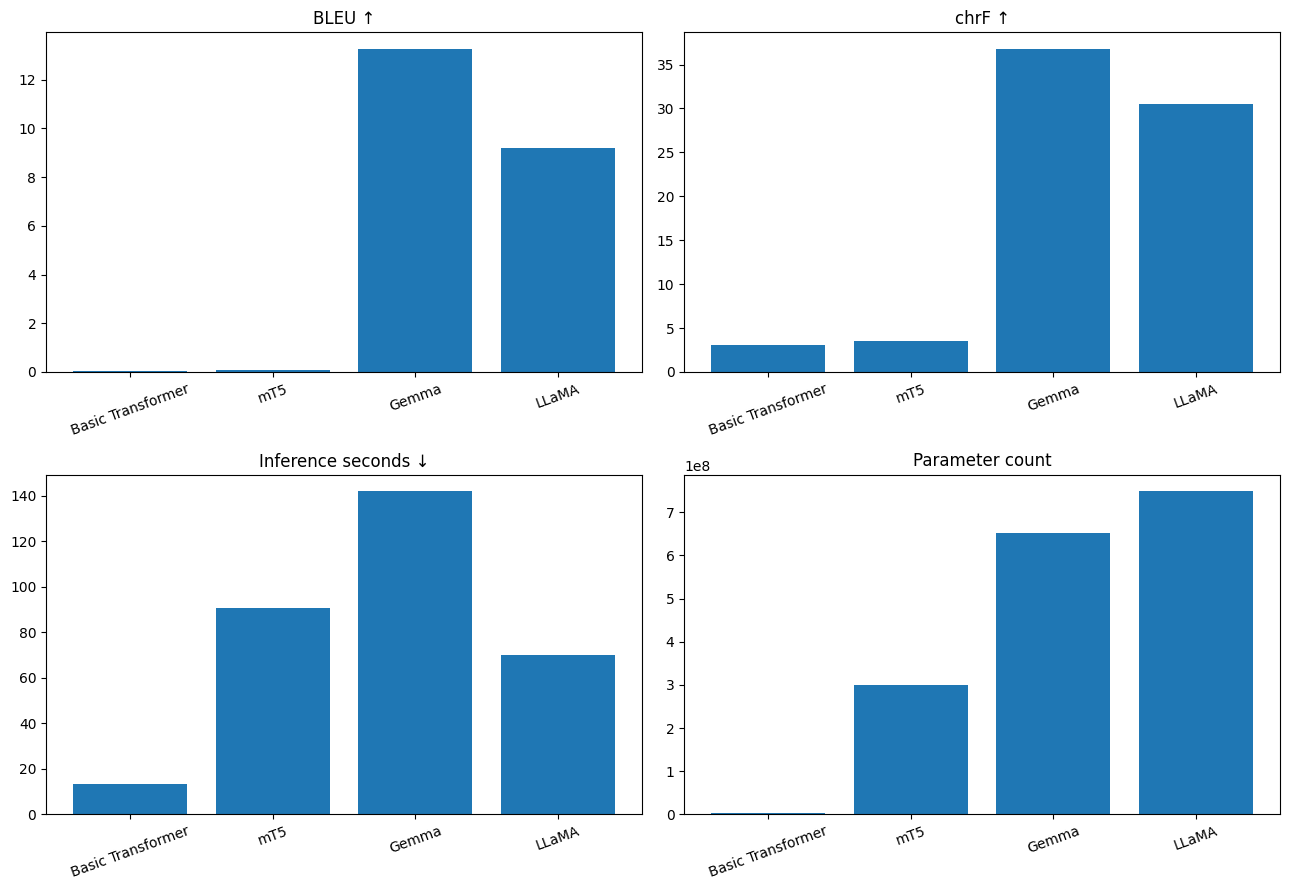

Files saved: model_comparison.csv, all_model_translations.csv, model_comparison.png


In [17]:
import matplotlib.pyplot as plt
comparison=pd.DataFrame(metrics);comparison.to_csv('model_comparison.csv',index=False)
translations=pd.DataFrame({'English':sources,'Reference_Spanish':references,**predictions});translations.to_csv('all_model_translations.csv',index=False)
print(comparison.to_string(index=False));print(translations.head(5).to_string(index=False))
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,(field,label) in zip(axes.flat,[('BLEU','BLEU ↑'),('chrF','chrF ↑'),('Inference_seconds','Inference seconds ↓'),('Parameters','Parameter count')]):
    ax.bar(comparison['Model'],comparison[field]);ax.set_title(label);ax.tick_params(axis='x',rotation=20)
plt.tight_layout();plt.savefig('model_comparison.png',dpi=180);plt.show()
print('Files saved: model_comparison.csv, all_model_translations.csv, model_comparison.png')

## 10. Responsible and ethical AI analysis

**Translation omissions and hallucinations.** In the held-out sample, the sentence "How it will answer, I cannot tell: I really don't know." was translated by LLaMA as "No te preocupes" ("Don't worry"), changing the message rather than translating it. Gemma returned "No lo sé", which captures uncertainty but omits the first clause. The basic Transformer emitted `<unk>` tokens, while mT5 produced `<extra_id_0>` and repeated words. These failures demonstrate that fluent output does not guarantee fidelity.

**Bias.** Gender-neutral English expressions may acquire unwarranted gender markers in Spanish. Test balanced occupations, pronouns and identities; audit errors by subgroup; and involve bilingual reviewers.

**Cultural misrepresentation.** Idioms, honorifics and literary references can be translated literally or lose their original nuance. Use context-rich examples and culturally informed human review.

**Sensitive content.** Errors involving negation, names, quantities, legal instructions, healthcare and personal information may cause harm. Apply domain-specific tests, privacy safeguards and mandatory human review for high-stakes uses.

**Limitations.** BLEU and chrF measure overlap with references rather than factual or cultural accuracy. The models also differ in parameter count, pretraining and adaptation method, so this is not a controlled architecture-only comparison.

## 11. Conclusions

All four systems were evaluated on the same 100 held-out English–Spanish sentence pairs with deterministic decoding. **Gemma** achieved the highest BLEU (**13.2806**) and chrF (**36.8286**) scores, followed by **LLaMA** (BLEU **9.1940**, chrF **30.5297**). The Basic Transformer (BLEU **0.0534**, chrF **3.0843**) and fine-tuned mT5 (BLEU **0.0785**, chrF **3.5691**) produced poor translations under the limited training setup.

The Basic Transformer had the shortest inference time (**13.56 s** for 100 sentences); Gemma took **142.09 s**. Recorded training times were **25.39 s** for the Basic Transformer and **63.23 s** for mT5. LLaMA and Gemma were evaluated with prompting and 4-bit quantization, without fine-tuning, so training time is not applicable.

Qualitative examples in `all_model_translations.csv` reveal unknown tokens, repetition, omissions and meaning changes. Gemma performed best by corpus-level overlap metrics, but its outputs still require human verification for high-stakes translation. Comparisons are influenced by pretraining, model scale, tokenization and adaptation strategy, not architecture alone.

## 12. Download results for GitHub
Run the cell below to create a ZIP of notebook outputs. **The `.ipynb` notebook must be downloaded separately from File → Download → Download .ipynb.** Do not include Hugging Face tokens or model weights in the GitHub repository.

In [18]:
import zipfile,os
files=['model_comparison.csv','model_comparison.png','all_model_translations.csv']+[name.lower().replace(' ','_')+'_translations.csv' for name in predictions]+[name.lower().replace(' ','_')+'_metrics.csv' for name in predictions]
with zipfile.ZipFile('vidya_results.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in files:
        if os.path.isfile(f):z.write(f)
print('Saved vidya_results.zip with',len(files),'candidate files')

Saved vidya_results.zip with 11 candidate files
